# Ridge Regression — IT24104098 (Jayasekara J.M.K.L)
Member 3 contribution: correlation/multicollinearity audit, ordinal feature
validation, and Ridge Regression 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

## 1. Load data 

In [2]:
DATA_PATH = "../data/student-mat.csv"
df_raw = pd.read_csv(DATA_PATH, sep=";")
print(f"Shape: {df_raw.shape}")

Shape: (395, 33)


## 2. Deterministic cleaning 



In [3]:
df = df_raw.copy()
categorical_cols = df_raw.select_dtypes(include="object").columns

for col in categorical_cols:
    df[col] = df[col].str.strip()

rows_before = len(df)
df = df.drop_duplicates()
rows_after = len(df)

print(f"Dropped {rows_before - rows_after} duplicate rows")
print(f"Shape after cleaning: {df.shape}")

Dropped 0 duplicate rows
Shape after cleaning: (395, 33)


C:\Users\indhu\AppData\Local\Temp\ipykernel_19012\3329187606.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_raw.select_dtypes(include="object").columns


## 3. Train/Test Split (identical call to the group notebook: same seed, same test_size)

In [4]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["G3"])
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Train shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")

Train shape: (316, 32)
Test shape: (79, 32)


## 4. Correlation & Multicollinearity Audit (train set only)


In [5]:
train_df = X_train.copy()
train_df["G3"] = y_train

numeric_train = train_df.select_dtypes(include=np.number)
pearson_corr = numeric_train.corr()
spearman_corr = numeric_train.corr(method="spearman")

print("Pearson — G1/G2/G3:")
print(pearson_corr.loc[["G1", "G2", "G3"], ["G1", "G2", "G3"]].round(3))

print("\nSpearman — G1/G2/G3:")
print(spearman_corr.loc[["G1", "G2", "G3"], ["G1", "G2", "G3"]].round(3))

Pearson — G1/G2/G3:
       G1     G2     G3
G1  1.000  0.833  0.792
G2  0.833  1.000  0.908
G3  0.792  0.908  1.000

Spearman — G1/G2/G3:
       G1     G2     G3
G1  1.000  0.886  0.873
G2  0.886  1.000  0.958
G3  0.873  0.958  1.000


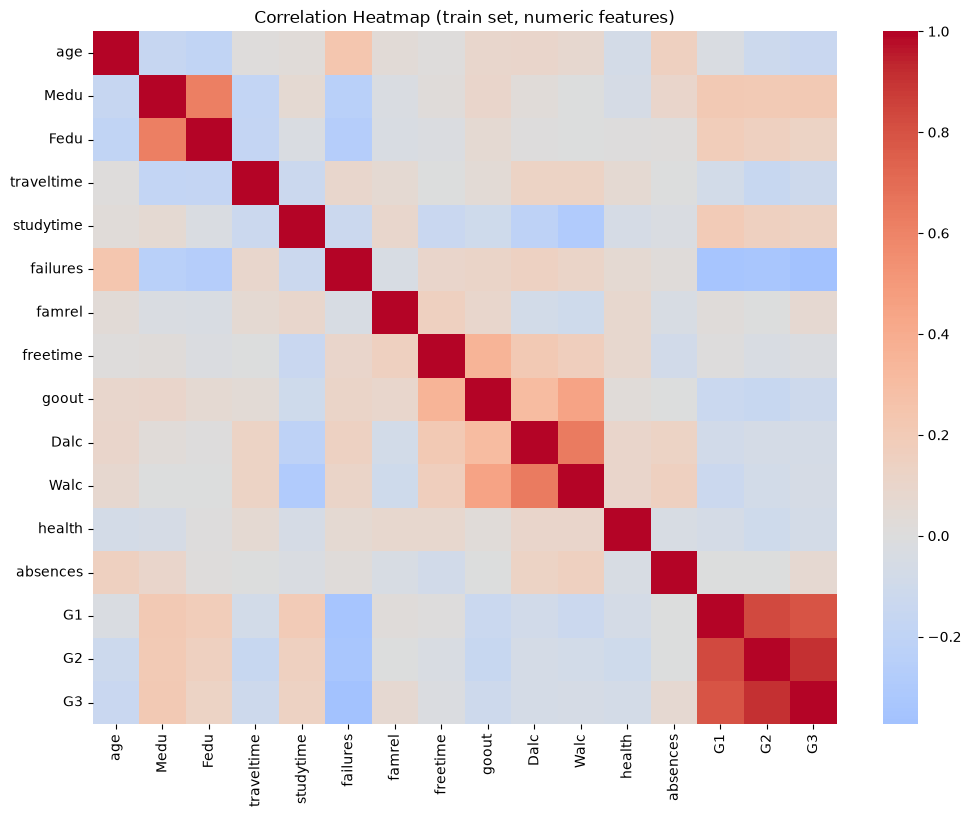

In [6]:
plt.figure(figsize=(12, 9))
sns.heatmap(pearson_corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap (train set, numeric features)")
plt.show()

In [7]:
from sklearn.linear_model import LinearRegression

def numeric_vif(frame):
    """Auxiliary-regression VIF; diagnostic on numeric predictors only, G3 excluded."""
    result = []
    for col in frame:
        others = frame.drop(columns=col)
        r2 = LinearRegression().fit(others, frame[col]).score(others, frame[col])
        result.append({"feature": col, "VIF": np.inf if 1 - r2 < 1e-12 else 1 / (1 - r2)})
    return pd.DataFrame(result).sort_values("VIF", ascending=False)

numeric_predictors = numeric_train.drop(columns=["G3"])
vif_table = numeric_vif(numeric_predictors)
print("VIF (numeric predictors, train set, G3 excluded):")
vif_table.round(3)

VIF (numeric predictors, train set, G3 excluded):


,feature,VIF
13,G1,3.654
14,G2,3.593
10,Walc,2.091
9,Dalc,1.757
1,Medu,1.748
2,Fedu,1.715
8,goout,1.502
5,failures,1.292
7,freetime,1.248
4,studytime,1.182


## 5. Preprocessing Pipeline 

In [8]:
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

binary_cols = ["school", "sex", "address", "famsize", "Pstatus",
                "schoolsup", "famsup", "paid", "activities", "nursery",
                "higher", "internet", "romantic"]

nominal_cols = ["Mjob", "Fjob", "reason", "guardian"]

numeric_cols_to_scale = ["age", "Medu", "Fedu", "traveltime", "studytime",
                          "failures", "famrel", "freetime", "goout", "Dalc",
                          "Walc", "health", "absences", "G1", "G2"]

def log_transform_absences(X):
    X = X.copy()
    X["absences"] = np.log1p(X["absences"])
    return X

absence_transformer = FunctionTransformer(log_transform_absences)

preprocessor = ColumnTransformer(
    transformers=[
        ("binary", OneHotEncoder(drop="if_binary"), binary_cols),
        ("nominal", OneHotEncoder(handle_unknown="ignore"), nominal_cols),
        ("numeric", StandardScaler(), numeric_cols_to_scale),
    ]
)

full_preprocessor = Pipeline(steps=[
    ("log_absences", absence_transformer),
    ("column_transform", preprocessor),
])

## 6. Ridge Regression 

In [9]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

ridge_pipeline = Pipeline(steps=[
    ("preprocessor", full_preprocessor),
    ("model", Ridge(random_state=RANDOM_STATE)),
])

ridge_param_grid = {
    "model__alpha": [0.1, 1.0, 10.0, 50.0, 100.0],
}

ridge_search = GridSearchCV(
    ridge_pipeline, ridge_param_grid, cv=5,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
ridge_search.fit(X_train, y_train)

print(f"Best alpha: {ridge_search.best_params_}")
print(f"Best CV RMSE: {-ridge_search.best_score_:.3f}")

ridge_best = ridge_search.best_estimator_

Best alpha: {'model__alpha': 10.0}
Best CV RMSE: 1.764


## 7. Test-Set Evaluation (touched once, consistent with the group protocol)

In [10]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

train_pred = ridge_best.predict(X_train)
test_pred = ridge_best.predict(X_test)

train_rmse = mean_squared_error(y_train, train_pred) ** 0.5
test_rmse = mean_squared_error(y_test, test_pred) ** 0.5
test_mae = mean_absolute_error(y_test, test_pred)
test_r2 = r2_score(y_test, test_pred)

print(f"Train RMSE: {train_rmse:.3f}")
print(f"Test RMSE:  {test_rmse:.3f}")
print(f"Train-Test Gap: {test_rmse - train_rmse:.3f}")
print(f"Test MAE:   {test_mae:.3f}")
print(f"Test R2:    {test_r2:.3f}")

Train RMSE: 1.597
Test RMSE:  2.261
Train-Test Gap: 0.664
Test MAE:   1.641
Test R2:    0.751


## 8. Ridge Coefficients (interpretation)

In [11]:
feature_names = ridge_best.named_steps["preprocessor"].named_steps["column_transform"].get_feature_names_out()
coefficients = ridge_best.named_steps["model"].coef_

coef_df = pd.DataFrame({"feature": feature_names, "coefficient": coefficients})
coef_df = coef_df.sort_values("coefficient", key=abs, ascending=False)
coef_df.head(15)

,feature,coefficient
44,numeric__G2,3.196194
43,numeric__G1,0.901443
42,numeric__absences,0.755706
5,binary__schoolsup_yes,0.553376
8,binary__activities_yes,-0.467593
24,nominal__reason_home,-0.386924
12,binary__romantic_yes,-0.356590
36,numeric__famrel,0.318275
1,binary__sex_M,0.314514
25,nominal__reason_other,0.269611
